1. Importar librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

2. carga de dataset

In [2]:
df = pd.read_csv('../data/clientes.csv')
df.shape

(7043, 21)

3. vista general dataset

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


4. Estrcutura dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


5. Estadisticas Descriptivas
Informaciópn variables numericas

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


6. Valores Nulos

In [6]:
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)
pd.DataFrame({'nulos': nulos, 'porcentaje_%': porcentaje}).sort_values('nulos', ascending=False)

,nulos,porcentaje_%
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


7. Filas Duplicadas

In [7]:
print('Filas totalmente duplicadas:', df.duplicated().sum())
print('customerID duplicados:', df['customerID'].duplicated().sum())

Filas totalmente duplicadas: 0
customerID duplicados: 0


8. 'TotalCharges' == Numerico

In [8]:
print(df['TotalCharges'].dtype)
df[df['tenure'] == 0][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

object


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [9]:
df[df['tenure'] == 0]['TotalCharges'].tolist()

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Dado que aparece como object --> pandas trata totalcharges como texto en vez de numero
Estos clientes tienen 0 meses de antiguedad y por eso su total charge aparece vacio

9. Variable Objetivo: Churn

In [10]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True).mul(100).round(2)
pd.DataFrame({'count': churn_counts, 'pct_%': churn_pct})

,count,pct_%
Churn,,
No,5174,73.46
Yes,1869,26.54


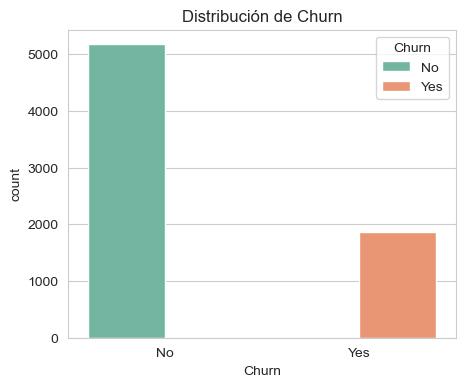

In [11]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2')
plt.title('Distribución de Churn')
plt.show()

Queremos que las clases esten balanceadas, no es el caso.
Esto condiciona el proprocesado y futuros modelos.

10. Variables Categoricas

In [12]:
cat_cols = df.select_dtypes(include='object').columns.drop('customerID')
for col in cat_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts())
    print()

--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     3095
Yes                    2422
No internet service    

11. Variables Numericas: Distribucion

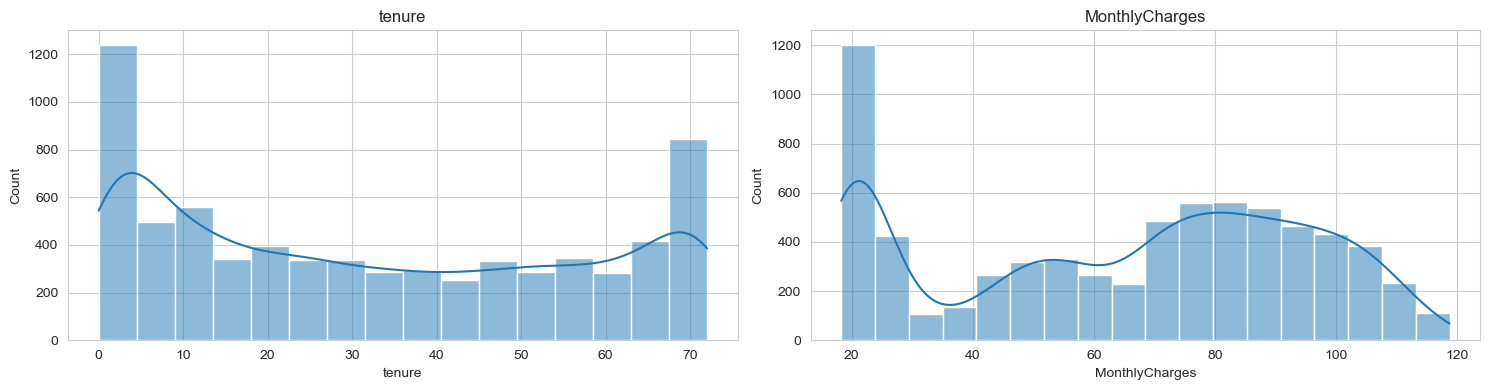

In [13]:
num_cols = ['tenure', 'MonthlyCharges',]
fig, axes = plt.subplots(1, 2, figsize=(15,4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

12. Variables Numericas vs Churn

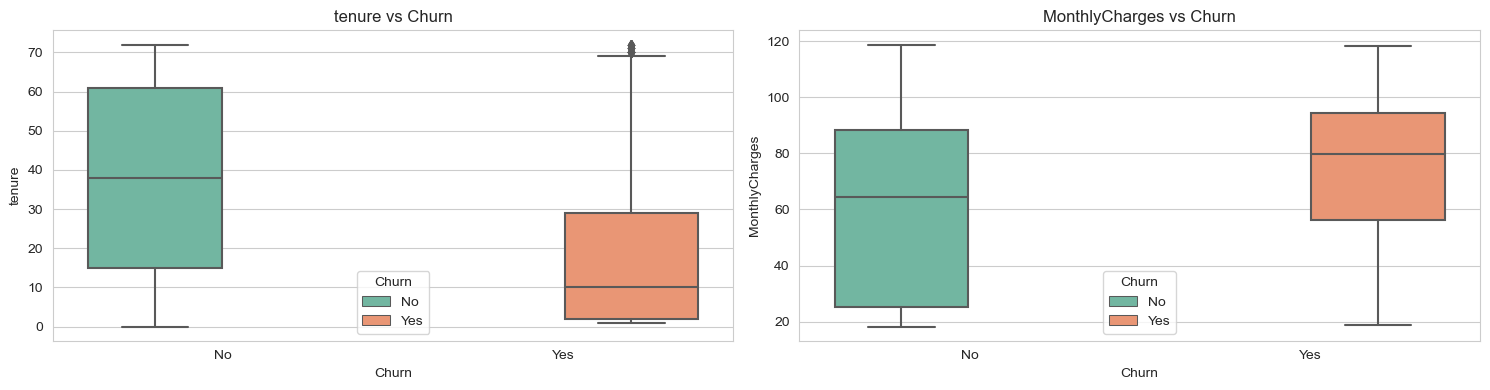

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15,4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', palette='Set2', ax=ax)
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()

13. Variables Categoricas vs Churn

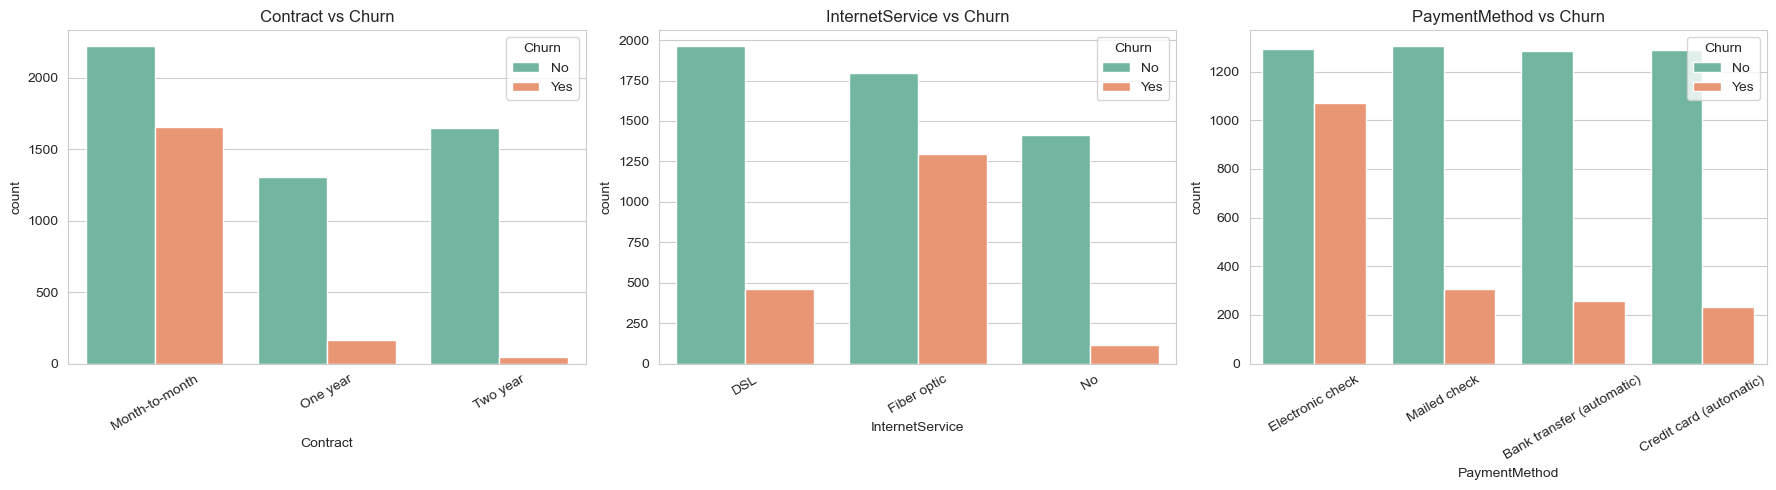

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    sns.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=ax)
    ax.set_title(f'{col} vs Churn')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

14. Hallzgos del EDA
- Forma del dataset: 7043 clientes, 21 variables
- Nulos: Ninguno
- Duplicados: Ninguno
- 'TotalCharges': Necesita conversion que se hará en "preprocesado.ipynb"
- Balance de Churn: 74% - 26% --> muy desbalanceado, se tendra que solucionar antes de crear modelo
- Variables vs Churn: A simple vista, variables numericas tienen mas relacion. Sobretodo 'tenure' y 'monthly charge'